# Reproducibility correction — 23 November 2026
This notebook processes **pre-segmented binary masks**; it does not implement the manuscript RGB/DBSCAN segmentation. The upstream mask provenance must be documented. Physical calibration is **unverified**: `px_to_um=1.0` denotes pixel units, not micrometres. Do not interpret area or MSE as physical units until a measured scale is supplied. Fourier radii use periodic interpolation of the extracted contour (not ray casting). Harmonic selection stops at first R²≥0.999 or relative MSE improvement below 1e-5, with tested H=1..179 for N=360. This is not global minimum-MSE optimization. Previously published tables and figures MUST be regenerated from original masks and reviewed before submission.


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, ifft
from scipy.ndimage import center_of_mass, label
from skimage.measure import regionprops, find_contours
from skimage.morphology import convex_hull_image
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import warnings
import seaborn as sns
from ipywidgets import interact, IntSlider
import os


warnings.filterwarnings('ignore')


In [16]:

# ==========================================================
# CONSTANTES
# ==========================================================

px_to_um = 3.952569  # PIXEL UNITS ONLY until calibration is verified; do not report physical µm
min_harmonics = 1
CALIBRATION_VERIFIED = False
TARGET_R2 = 0.999
RELATIVE_MSE_TOL = 1e-5
max_harmonics = 300

# ==========================================================
# EXTRAÇÃO POLAR VIA CONTORNO (1° POR PASSO)
# ==========================================================

def calculate_radii(region, center, num_angles=360):
    """
    Extrai r(θ) a partir do contorno real do grão,
    com amostragem angular fixa de 1°.
    """

    contours = find_contours(region.astype(float), 0.5)

    if len(contours) == 0:
        raise ValueError("Contorno não encontrado.")

    contour = max(contours, key=len)

    cy, cx = center

    y = contour[:, 0]
    x = contour[:, 1]

    x_rel = x - cx
    y_rel = y - cy

    angles = np.arctan2(y_rel, x_rel)
    angles = np.mod(angles, 2*np.pi)

    radii = np.sqrt(x_rel**2 + y_rel**2)

    order = np.argsort(angles)
    angles = angles[order]
    radii = radii[order]

    unique_angles, unique_indices = np.unique(angles, return_index=True)
    angles = unique_angles
    radii = radii[unique_indices]

    # Malha angular uniforme (1 grau)
    theta_uniform = np.linspace(0, 2*np.pi, num_angles, endpoint=False)

    # Reamostragem periódica (sem suavização)
    radii_interp = np.interp(
        theta_uniform,
        angles,
        radii,
        period=2*np.pi
    )

    return theta_uniform, radii_interp * px_to_um


# ==========================================================
# FOURIER
# ==========================================================

def fourier_series(radii, num_harmonics):
    coeffs = fft(radii)
    coeffs[num_harmonics+1:-num_harmonics] = 0
    return np.real(ifft(coeffs))


def calculate_fourier_descriptors(radii, n_descriptors=64):
    fft_coeffs = fft(radii)
    D = np.abs(fft_coeffs) / len(fft_coeffs)
    return D[:n_descriptors]


def calculate_roughness_coefficients(coeffs, j, k):
    a_n = np.real(coeffs[j:k+1])
    b_n = np.imag(coeffs[j:k+1])
    return np.sqrt(0.5 * np.sum(a_n**2 + b_n**2))


# ==========================================================
# DESCRITORES GEOMÉTRICOS
# ==========================================================

def calculate_geometric_descriptors(region):
    props = regionprops(region.astype(int))[0]

    area = props.area
    perimeter = props.perimeter

    CI = (4 * np.pi * area) / (perimeter ** 2) if perimeter > 0 else 0

    convex_hull = convex_hull_image(region)
    convex_props = regionprops(convex_hull.astype(int))[0]
    convex_perimeter = convex_props.perimeter

    if perimeter > convex_perimeter:
        RE = convex_perimeter / perimeter
    else:
        RE = min(1.0, convex_perimeter / perimeter) if perimeter > 0 else np.nan

    equivalent_radius = np.sqrt(area / np.pi)
    RO = equivalent_radius / (perimeter / (2 * np.pi)) if perimeter > 0 else 0

    return RO, CI, RE


# ==========================================================
# ANÁLISE PRINCIPAL
# ==========================================================

def analyze_grains(binary_mask):

    labels_array = label(binary_mask)[0]
    num_labels = np.max(labels_array)

    results = {
        'labels': [],
        'areas': [],
        'centers': [],
        'MAE': [],
        'MSE': [],
        'R2': [],
        'harmonics': [],
        'radii_real': [],
        'radii_fourier': [],
        'angles': [],
        'history': []   # <-- histórico de convergência por grão
    }

    for label_idx in range(1, num_labels + 1):

        region = (labels_array == label_idx)

        if np.sum(region) < 20:
            continue

        center = center_of_mass(region)
        area = np.sum(region) * (px_to_um ** 2)

        try:
            angles, radii = calculate_radii(region, center)
        except:
            continue

        target_r2 = TARGET_R2
        epsilon = RELATIVE_MSE_TOL

        best_harmonics = min_harmonics
        best_mse = float('inf')
        best_r2 = -np.inf
        best_radii_fourier = None
        previous_mse = None

        upper_limit = min(max_harmonics, len(radii)//2)

        # Histórico de evolução do grão
        grain_history = {
            "harmonics": [],
            "MSE": [],
            "R2": []
        }

        for num_harmonics in range(min_harmonics, upper_limit):  # 1..179 for N=360 (Nyquist excluded)

            radii_fourier_temp = fourier_series(radii, num_harmonics)

            mse = mean_squared_error(radii, radii_fourier_temp)
            r2 = r2_score(radii, radii_fourier_temp)

            # Armazenar histórico completo
            grain_history["harmonics"].append(num_harmonics)
            grain_history["MSE"].append(mse)
            grain_history["R2"].append(r2)

            if r2 >= target_r2:
                best_harmonics = num_harmonics
                best_mse = mse
                best_r2 = r2
                best_radii_fourier = radii_fourier_temp
                break

            if previous_mse is not None:
                improvement = abs(previous_mse - mse) / max(previous_mse, np.finfo(float).eps)
                if improvement < epsilon:
                    break

            previous_mse = mse

            best_harmonics = num_harmonics
            best_mse = mse
            best_r2 = r2
            best_radii_fourier = radii_fourier_temp

        if best_radii_fourier is None:
            continue

        mae = mean_absolute_error(radii, best_radii_fourier)

        results['labels'].append(label_idx)
        results['areas'].append(area)
        results['centers'].append(center)
        results['MAE'].append(mae)
        results['MSE'].append(best_mse)
        results['R2'].append(best_r2)
        results['harmonics'].append(best_harmonics)
        results['radii_real'].append(radii)
        results['radii_fourier'].append(best_radii_fourier)
        results['angles'].append(angles)
        results['history'].append(grain_history)

        print(f"Grão {label_idx} | Harmônicos: {best_harmonics} | R²: {best_r2:.4f}")

    return results, labels_array


# ==========================================================
# EXECUÇÃO DIRETA
# ==========================================================

if __name__ == "__main__":

    from PIL import Image

    mask_path = "/home/victor/correção artigo/lamina 12/saida_segmentacao_graos01/axes_individuais/08_graos_binaria_sem_borda_com_lacuna.png"

    mask_img = Image.open(mask_path)
    mask_array = np.array(mask_img) > 0

    results, labels_array = analyze_grains(mask_array)

    print("\nProcessamento finalizado.")

Grão 1 | Harmônicos: 63 | R²: 0.9990
Grão 2 | Harmônicos: 152 | R²: 0.9908
Grão 3 | Harmônicos: 89 | R²: 0.9990
Grão 4 | Harmônicos: 155 | R²: 0.9990
Grão 5 | Harmônicos: 36 | R²: 0.9990
Grão 6 | Harmônicos: 63 | R²: 0.9990
Grão 7 | Harmônicos: 85 | R²: 0.9991
Grão 8 | Harmônicos: 53 | R²: 0.9982
Grão 9 | Harmônicos: 61 | R²: 0.9991
Grão 10 | Harmônicos: 130 | R²: 0.9987
Grão 11 | Harmônicos: 39 | R²: 0.9990
Grão 12 | Harmônicos: 156 | R²: 0.9990
Grão 13 | Harmônicos: 67 | R²: 0.9990
Grão 14 | Harmônicos: 41 | R²: 0.9991
Grão 15 | Harmônicos: 27 | R²: 0.9990
Grão 16 | Harmônicos: 122 | R²: 0.9945
Grão 17 | Harmônicos: 32 | R²: 0.9990
Grão 18 | Harmônicos: 117 | R²: 0.9961
Grão 19 | Harmônicos: 39 | R²: 0.9990
Grão 20 | Harmônicos: 164 | R²: 0.9990
Grão 21 | Harmônicos: 69 | R²: 0.9990
Grão 22 | Harmônicos: 117 | R²: 0.9990
Grão 23 | Harmônicos: 152 | R²: 0.9991
Grão 24 | Harmônicos: 117 | R²: 0.9990
Grão 25 | Harmônicos: 68 | R²: 0.9990
Grão 26 | Harmônicos: 146 | R²: 0.9990
Grão 27 | 

In [17]:
results, labels_array = analyze_grains(mask_array)

print("\nProcessamento finalizado.")

Grão 1 | Harmônicos: 63 | R²: 0.9990
Grão 2 | Harmônicos: 152 | R²: 0.9908
Grão 3 | Harmônicos: 89 | R²: 0.9990
Grão 4 | Harmônicos: 155 | R²: 0.9990
Grão 5 | Harmônicos: 36 | R²: 0.9990
Grão 6 | Harmônicos: 63 | R²: 0.9990
Grão 7 | Harmônicos: 85 | R²: 0.9991
Grão 8 | Harmônicos: 53 | R²: 0.9982
Grão 9 | Harmônicos: 61 | R²: 0.9991
Grão 10 | Harmônicos: 130 | R²: 0.9987
Grão 11 | Harmônicos: 39 | R²: 0.9990
Grão 12 | Harmônicos: 156 | R²: 0.9990
Grão 13 | Harmônicos: 67 | R²: 0.9990
Grão 14 | Harmônicos: 41 | R²: 0.9991
Grão 15 | Harmônicos: 27 | R²: 0.9990
Grão 16 | Harmônicos: 122 | R²: 0.9945
Grão 17 | Harmônicos: 32 | R²: 0.9990
Grão 18 | Harmônicos: 117 | R²: 0.9961
Grão 19 | Harmônicos: 39 | R²: 0.9990
Grão 20 | Harmônicos: 164 | R²: 0.9990
Grão 21 | Harmônicos: 69 | R²: 0.9990
Grão 22 | Harmônicos: 117 | R²: 0.9990
Grão 23 | Harmônicos: 152 | R²: 0.9991
Grão 24 | Harmônicos: 117 | R²: 0.9990
Grão 25 | Harmônicos: 68 | R²: 0.9990
Grão 26 | Harmônicos: 146 | R²: 0.9990
Grão 27 | 

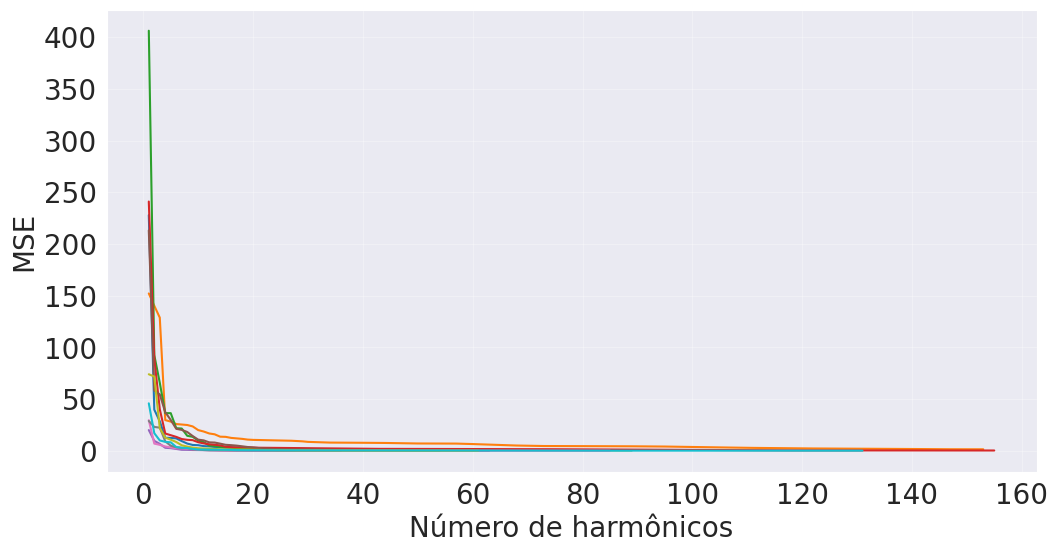

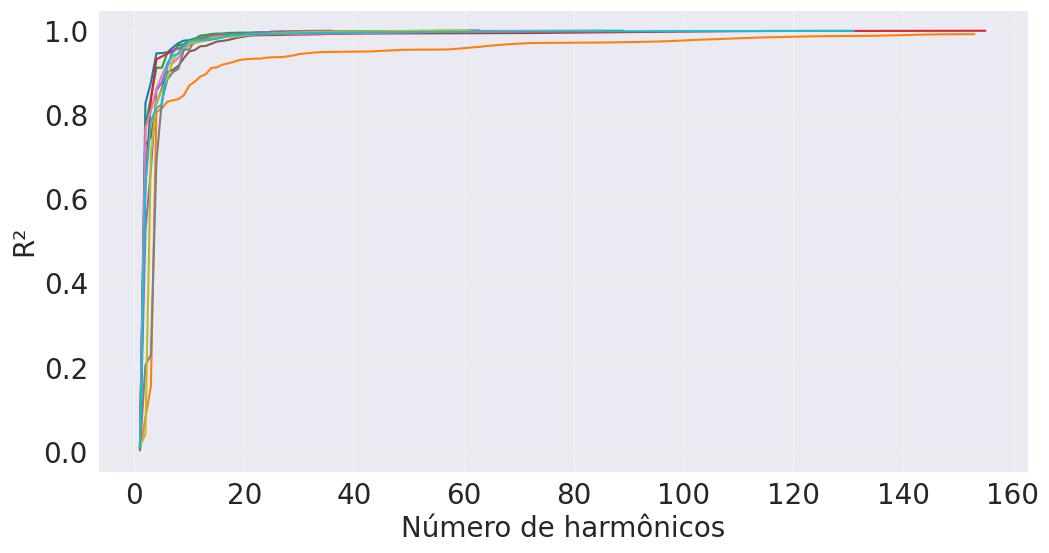

In [18]:
# ==========================================================
# EVOLUÇÃO DE 10 GRÃOS: MSE E R² vs NÚMERO DE HARMÔNICOS
# ==========================================================

import matplotlib.pyplot as plt
import numpy as np
import random

# ----------------------------------------------------------
# Seleção de 10 grãos
# ----------------------------------------------------------
n_grains_plot = 10

total_grains = len(results["labels"])
n_select = min(n_grains_plot, total_grains)

# Seleção dos primeiros 10 grãos:
selected_indices = list(range(n_select))

# Se preferir aleatório, use esta linha no lugar da anterior:
# selected_indices = random.sample(range(total_grains), n_select)

# ----------------------------------------------------------
# GRÁFICO 1 — Evolução do MSE
# ----------------------------------------------------------
plt.figure(figsize=(12, 6))

for idx in selected_indices:
    grain_label = results["labels"][idx]
    grain_history = results["history"][idx]

    plt.plot(
        grain_history["harmonics"],
        grain_history["MSE"],
        linewidth=1.5,
        label=f"Grão {grain_label}"
    )

plt.xlabel("Número de harmônicos", fontsize=20)
plt.ylabel("MSE", fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.title("Evolução do MSE com o aumento do número de harmônicos")
plt.grid(True, alpha=0.3)
#plt.legend(ncol=2, fontsize=9)
#plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# GRÁFICO 2 — Evolução do R²
# ----------------------------------------------------------
plt.figure(figsize=(12, 6))

for idx in selected_indices:
    grain_label = results["labels"][idx]
    grain_history = results["history"][idx]

    plt.plot(
        grain_history["harmonics"],
        grain_history["R2"],
        linewidth=1.5,
        label=f"Grão {grain_label}"
    )

plt.xlabel("Número de harmônicos", fontsize=20)
plt.ylabel("R²", fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.title("Evolução do R² com o aumento do número de harmônicos")
plt.grid(True, alpha=0.3)
#plt.legend(ncol=2, fontsize=9)
#plt.tight_layout()
plt.show()

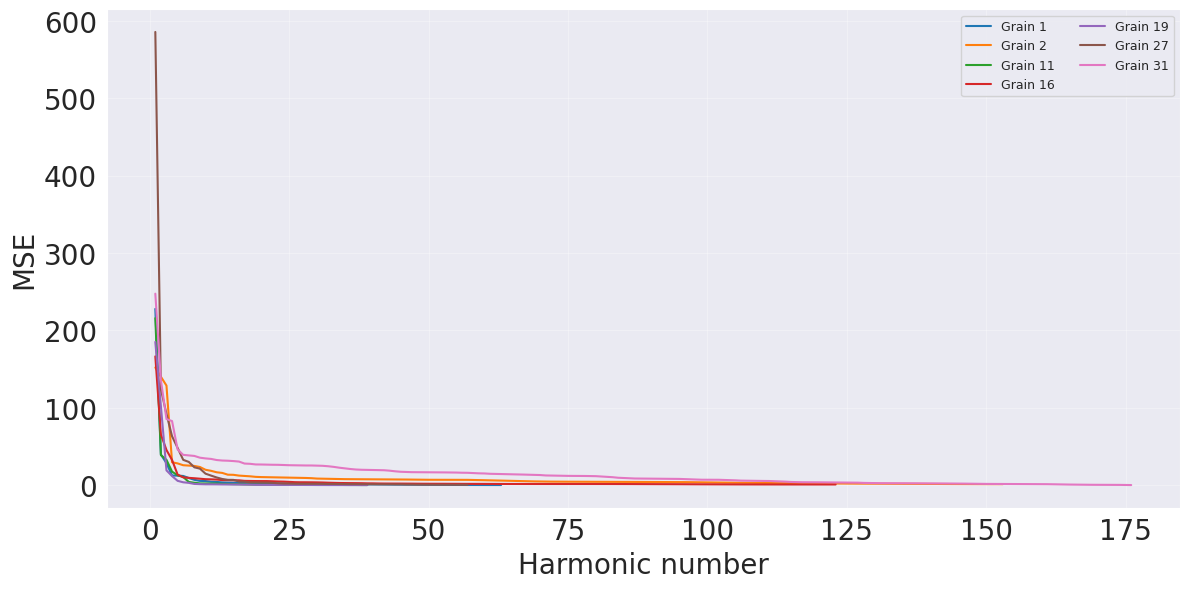

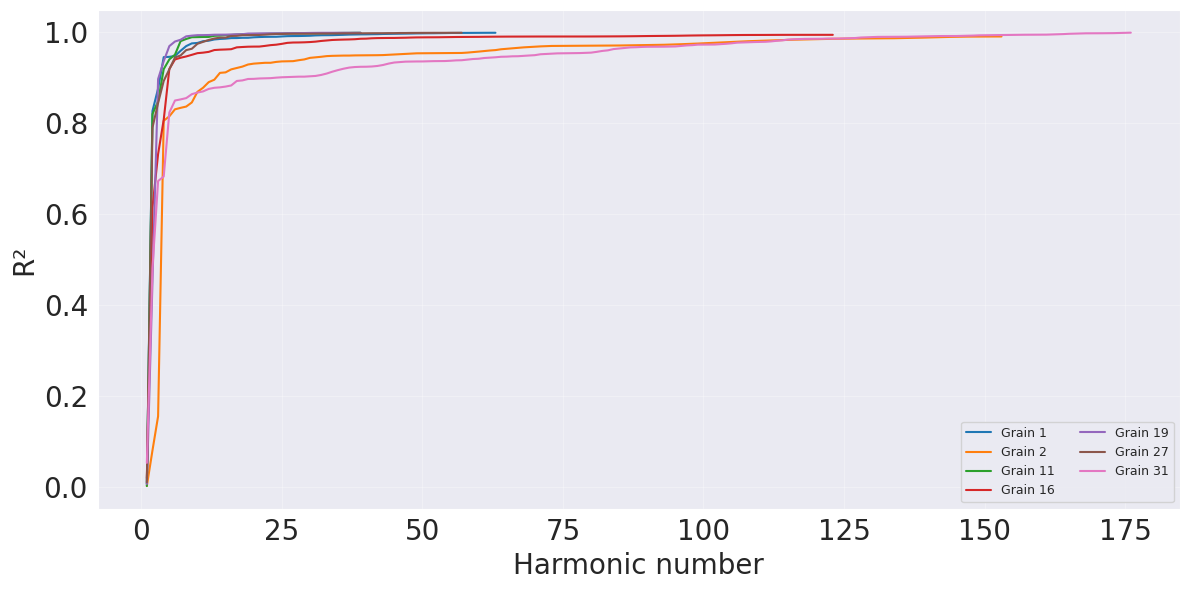

In [19]:
# Exemplo: escolher 10 grãos específicos pelo índice interno do results
selected_indices = [0, 1, 10, 15,18,26,30]

plt.figure(figsize=(12, 6))
for idx in selected_indices:
    grain_label = results["labels"][idx]
    grain_history = results["history"][idx]
    plt.plot(grain_history["harmonics"], grain_history["MSE"], linewidth=1.5, label=f"Grain {grain_label}")

plt.xlabel("Harmonic number", fontsize=20)
plt.ylabel("MSE", fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.title("Evolução do MSE com o aumento do número de harmônicos")
plt.grid(True, alpha=0.3)
plt.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
for idx in selected_indices:
    grain_label = results["labels"][idx]
    grain_history = results["history"][idx]
    plt.plot(grain_history["harmonics"], grain_history["R2"], linewidth=1.5, label=f"Grain {grain_label}")

plt.xlabel("Harmonic number", fontsize=20)
plt.ylabel("R²", fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.title("Evolução do R² com o aumento do número de harmônicos")
plt.grid(True, alpha=0.3)
plt.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

In [20]:
# ==========================================================
# VISUALIZAÇÃO: GRÃO REAL vs CONTORNO EXTRAÍDO
# ==========================================================


def plot_real_vs_contour(results, labels_array, px_to_um):

    if len(results['labels']) == 0:
        print("Nenhum grão válido encontrado.")
        return

    def _plot(grain_index):

        idx = grain_index - 1
        label_id = results['labels'][idx]

        region = (labels_array == label_id)

        angles = results['angles'][idx]
        radii = results['radii_real'][idx]
        center = results['centers'][idx]
        cy, cx = center

        # Conversão polar → cartesiano (retornando para pixel)
        x_contour = cx + (radii / px_to_um) * np.cos(angles)
        y_contour = cy + (radii / px_to_um) * np.sin(angles)

        # ======================================================
        # PLOT
        # ======================================================

        fig, ax = plt.subplots(1, 2, figsize=(10, 5))
        sns.axes_style('darkgrid')

        # 1) Máscara real
        ax[0].imshow(region, cmap='gray')
        ax[0].set_title(f'Grão {grain_index} - Máscara Real')
        ax[0].axis('off')

        # 2) Contorno polar reconstruído
        ax[1].imshow(region, cmap='gray')
        ax[1].plot(x_contour, y_contour, 'r-', linewidth=1)
        ax[1].set_title('Contorno Polar Reconstruído')
        ax[1].axis('off')

        plt.tight_layout()
        plt.show()

    interact(
        _plot,
        grain_index=IntSlider(
            min=1,
            max=len(results['labels']),
            step=1,
            value=1,
            description='Grão'
        )
    )
results, labels_array = analyze_grains(mask_array)
plot_real_vs_contour(results, labels_array, px_to_um)

Grão 1 | Harmônicos: 63 | R²: 0.9990
Grão 2 | Harmônicos: 152 | R²: 0.9908
Grão 3 | Harmônicos: 89 | R²: 0.9990
Grão 4 | Harmônicos: 155 | R²: 0.9990
Grão 5 | Harmônicos: 36 | R²: 0.9990
Grão 6 | Harmônicos: 63 | R²: 0.9990
Grão 7 | Harmônicos: 85 | R²: 0.9991
Grão 8 | Harmônicos: 53 | R²: 0.9982
Grão 9 | Harmônicos: 61 | R²: 0.9991
Grão 10 | Harmônicos: 130 | R²: 0.9987
Grão 11 | Harmônicos: 39 | R²: 0.9990
Grão 12 | Harmônicos: 156 | R²: 0.9990
Grão 13 | Harmônicos: 67 | R²: 0.9990
Grão 14 | Harmônicos: 41 | R²: 0.9991
Grão 15 | Harmônicos: 27 | R²: 0.9990
Grão 16 | Harmônicos: 122 | R²: 0.9945
Grão 17 | Harmônicos: 32 | R²: 0.9990
Grão 18 | Harmônicos: 117 | R²: 0.9961
Grão 19 | Harmônicos: 39 | R²: 0.9990
Grão 20 | Harmônicos: 164 | R²: 0.9990
Grão 21 | Harmônicos: 69 | R²: 0.9990
Grão 22 | Harmônicos: 117 | R²: 0.9990
Grão 23 | Harmônicos: 152 | R²: 0.9991
Grão 24 | Harmônicos: 117 | R²: 0.9990
Grão 25 | Harmônicos: 68 | R²: 0.9990
Grão 26 | Harmônicos: 146 | R²: 0.9990
Grão 27 | 

interactive(children=(IntSlider(value=1, description='Grão', max=937, min=1), Output()), _dom_classes=('widget…

In [21]:
# ==========================================================
# VISUALIZAÇÃO INTERATIVA DOS GRÃOS (COMPARAÇÃO POLAR)
# COM FUNDO DARKGRID
# ==========================================================

import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact, IntSlider
import numpy as np

sns.set_style('darkgrid')

def plot_grain_analysis(results):

    if len(results['labels']) == 0:
        print("Nenhum grão válido encontrado.")
        return

    def _plot(grain_index):

        idx = grain_index - 1
        
        angles = results['angles'][idx]
        radii_real = results['radii_real'][idx]
        radii_fourier = results['radii_fourier'][idx]
        harmonics = results['harmonics'][idx]

        # ======================================================
        # FIGURA 1 — CONTORNO REAL
        # ======================================================
        fig1 = plt.figure(figsize=(6, 6))
        ax1 = fig1.add_subplot(111, projection='polar')
        ax1.plot(angles, radii_real, linewidth=2)
        #ax1.set_title(f'Grain {grain_index} — real outline\nHarmonics: {harmonics}')
        ax1.grid(True)

        # Ajuste manual para melhor contraste
        ax1.set_facecolor('#EAEAF2')

        plt.tight_layout()
        plt.show()

        # ======================================================
        # FIGURA 2 — MODELO SÉRIE DE FOURIER
        # ======================================================
        fig2 = plt.figure(figsize=(6, 6))
        ax2 = fig2.add_subplot(111, projection='polar')
        ax2.plot(angles, radii_fourier, linewidth=2, color='red')
        #ax2.set_title(f'Grain {grain_index} — Série de Fourier\nHarmônicos: {harmonics}')
        ax2.grid(True)

        ax2.set_facecolor('#EAEAF2')

        plt.tight_layout()
        plt.show()

    interact(
        _plot,
        grain_index=IntSlider(
            min=1,
            max=len(results['labels']),
            step=1,
            value=1,
            description='Grão'
        )
    )

plot_grain_analysis(results)

interactive(children=(IntSlider(value=1, description='Grão', max=937, min=1), Output()), _dom_classes=('widget…

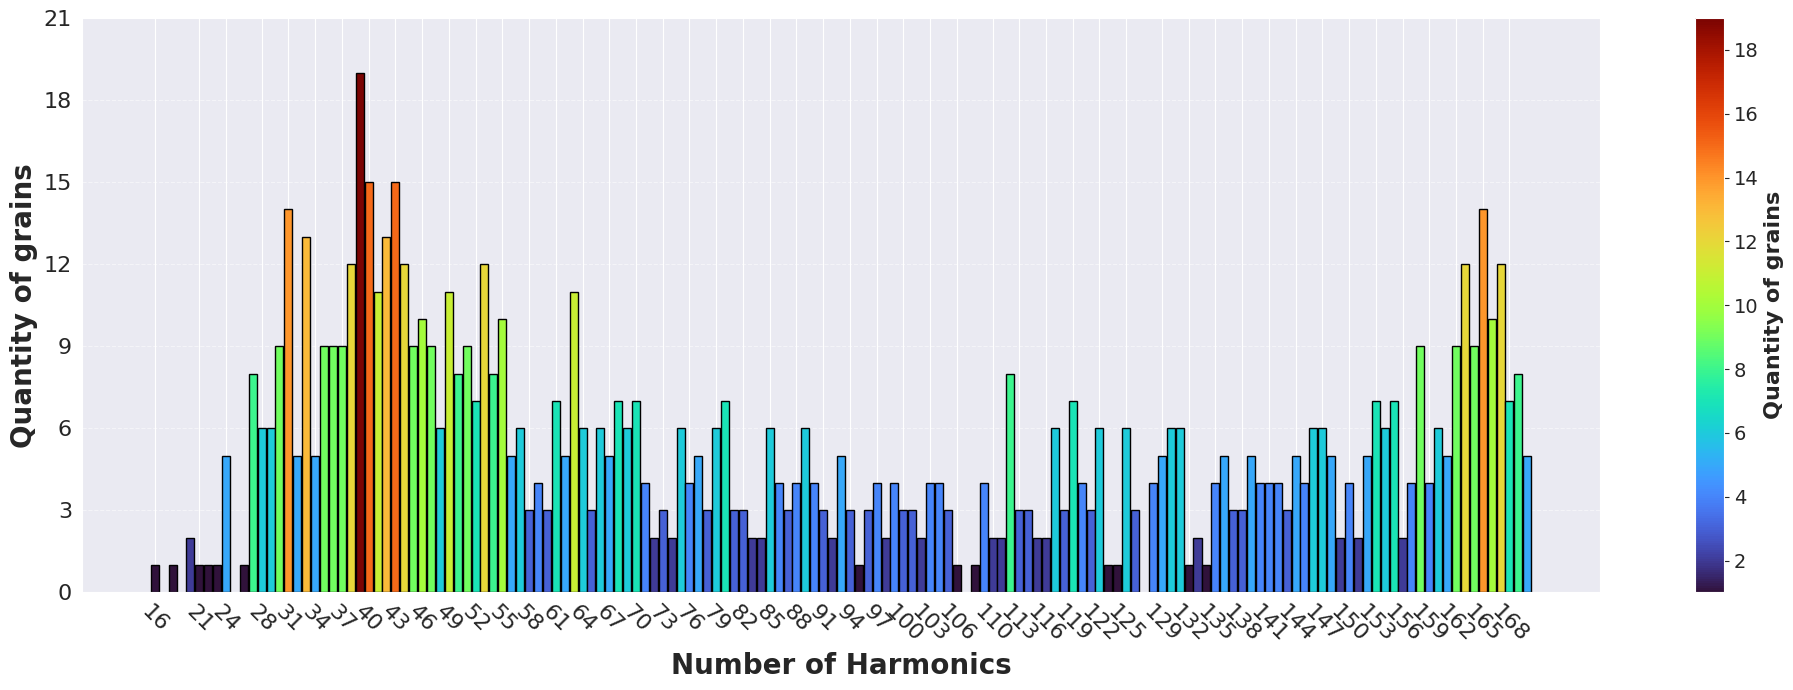

Resumo estatístico:
Média: 88.90
Mediana: 76.50
Desvio padrão: 47.81
Mínimo: 16
Máximo: 170


In [23]:
# ==========================================================
# HISTOGRAMA AGRUPADO POR INTERVALOS COM PALETA DE CORES
# ==========================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize

def plot_harmonics_histogram(results, max_harmonic=170, bin_width=1):
    harmonics = np.array(results['harmonics'])

    if len(harmonics) == 0:
        print("Nenhum grão válido foi processado.")
        return

    # -------------------------
    # Filtragem
    # -------------------------
    filtered = harmonics[harmonics <= max_harmonic]

    if len(filtered) == 0:
        print("Nenhum grão dentro do limite especificado.")
        return

    # -------------------------
    # Contagem por valor inteiro de harmônico
    # -------------------------
    values, counts = np.unique(filtered, return_counts=True)

    # Caso queira agrupar por largura maior que 1
    if bin_width > 1:
        bin_edges = np.arange(values.min(), values.max() + bin_width, bin_width)
        hist_counts, edges = np.histogram(filtered, bins=bin_edges)
        centers = (edges[:-1] + edges[1:]) / 2

        # manter apenas bins realmente usados
        mask = hist_counts > 0
        x_vals = centers[mask]
        y_vals = hist_counts[mask]
        widths = np.diff(edges)[mask]
    else:
        x_vals = values
        y_vals = counts
        widths = np.full_like(x_vals, 0.9, dtype=float)

    # -------------------------
    # Mapeamento de cores pela frequência
    # -------------------------
    norm = Normalize(vmin=np.min(y_vals), vmax=np.max(y_vals))
    cmap = cm.get_cmap("turbo")
    colors = cmap(norm(y_vals))

    # -------------------------
    # Plot
    # -------------------------
    plt.figure(figsize=(20, 7))
    bars = plt.bar(
        x_vals,
        y_vals,
        width=widths,
        color=colors,
        edgecolor="black",
        align="center"
    )

    plt.xlabel("Number of Harmonics", fontsize=20, fontweight="bold")
    plt.ylabel("Quantity of grains", fontsize=20, fontweight="bold")

    # -------------------------
    # Eixo X: mostrar apenas valores usados
    # -------------------------
    if len(x_vals) <= 40:
        plt.xticks(x_vals, rotation=-45, fontsize=16)
    else:
        step = max(1, len(x_vals) // 40)
        plt.xticks(x_vals[::step], rotation=-45, fontsize=16)

    # -------------------------
    # Eixo Y
    # -------------------------
    y_max = np.max(y_vals)
    step_y = max(1, int(np.ceil(y_max / 8)))
    plt.yticks(np.arange(0, y_max + step_y, step_y), fontsize=16)

    # -------------------------
    # Barra de cores
    # -------------------------
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=plt.gca())
    cbar.set_label("Quantity of grains", fontsize=16, fontweight="bold")
    cbar.ax.tick_params(labelsize=14)

    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    # -------------------------
    # Estatísticas adicionais
    # -------------------------
    print("Resumo estatístico:")
    print(f"Média: {np.mean(filtered):.2f}")
    print(f"Mediana: {np.median(filtered):.2f}")
    print(f"Desvio padrão: {np.std(filtered):.2f}")
    print(f"Mínimo: {np.min(filtered)}")
    print(f"Máximo: {np.max(filtered)}")


plot_harmonics_histogram(results, max_harmonic=170, bin_width=1)

In [24]:
# ==========================================================
# VISUALIZAÇÃO r(θ) EM FORMATO CARTESIANO (ÂNGULO × RAIO)
# ==========================================================

def plot_radial_function(results):

    if len(results['labels']) == 0:
        print("Nenhum grão válido encontrado.")
        return

    def _plot(grain_index):

        idx = grain_index - 1

        angles = results['angles'][idx]
        radii_real = results['radii_real'][idx]
        radii_fourier = results['radii_fourier'][idx]
        harmonics = results['harmonics'][idx]
        r2 = results['R2'][idx]

        # Converter ângulo para graus
        angles_deg = np.degrees(angles)

        # Garantir ordenação crescente (robustez numérica)
        order = np.argsort(angles_deg)
        angles_deg = angles_deg[order]
        radii_real = radii_real[order]
        radii_fourier = radii_fourier[order]

        # ======================================================
        # PLOT
        # ======================================================

        fig, ax = plt.subplots(1, 2, figsize=(18, 4))
        sns.axes_style('darkgrid')

        # -----------------------------
        # 1) CONTORNO REAL
        # -----------------------------
        ax[0].plot(angles_deg, radii_real, label= 'Real outline', color='blue')
        ax[0].set_title(f'Grain {grain_index} - Real grain', fontsize= 18)
        ax[0].set_xlabel("Angle (degrees)", fontsize= 18)
        ax[0].set_ylabel("Raio (µm)", fontsize= 18)
        ax[0].set_xlim(0, 360)
        ax[0].tick_params(axis='both', labelsize=18)
        ax[0].grid(True)

        # -----------------------------
        # 2) SÉRIE DE FOURIER
        # -----------------------------
        ax[1].plot(angles_deg, radii_fourier, label= 'Fourier series', color='red')
        ax[1].set_title(
            f'Reconstruction using Fourier series\nNumber of harmonics: {harmonics}', fontsize= 18
        )
        ax[1].set_xlabel("Angle (degrees)", fontsize= 18)
        ax[1].set_ylabel("Distance (µm)", fontsize= 18)
        ax[1].set_xlim(0, 360)
        ax[1].tick_params(axis='both', labelsize=18)
        ax[1].grid(True)

        plt.tight_layout()
        plt.legend()
        plt.show()

    interact(
        _plot,
        grain_index=IntSlider(
            min=1,
            max=len(results['labels']),
            step=1,
            value=1,
            description='Grão'
        )
    )

plot_radial_function(results)

interactive(children=(IntSlider(value=1, description='Grão', max=937, min=1), Output()), _dom_classes=('widget…

In [25]:
from scipy.ndimage import label
from skimage.measure import regionprops
from skimage.morphology import convex_hull_image

def calculate_shape_descriptors(binary_mask, px_to_um=1.0):

    labels_array = label(binary_mask)[0]
    num_labels = np.max(labels_array)

    descriptors = {
        "Label": [],
        "Área (pixel²)": [],
        "Perímetro (pixel)": [],
        "Circularidade": [],
        "Arredondamento": [],
        "Regularidade": []
    }

    for label_idx in range(1, num_labels + 1):

        region = (labels_array == label_idx)

        if np.sum(region) < 20:
            continue

        props = regionprops(region.astype(int))[0]

        # ---------------------------------
        # Área e Perímetro (convertidos)
        # ---------------------------------
        area = props.area * (px_to_um ** 2)
        perimeter = props.perimeter * px_to_um

        if perimeter == 0:
            continue

        # ---------------------------------
        # 1) Circularidade
        # ---------------------------------
        circularity = (4 * np.pi * area) / (perimeter ** 2)

        # ---------------------------------
        # 2) Arredondamento
        # ---------------------------------
        r_eq = np.sqrt(area / np.pi)
        r_per = perimeter / (2 * np.pi)
        roundness = r_eq / r_per

        # ---------------------------------
        # 3) Regularidade (Convexidade)
        # ---------------------------------
        convex = convex_hull_image(region)
        convex_props = regionprops(convex.astype(int))[0]
        convex_perimeter = convex_props.perimeter * px_to_um

        regularity = min(1.0, convex_perimeter / perimeter)  # perimeter-based convexity; discrete contours may exceed 1 slightly

        # ---------------------------------
        # Armazenamento
        # ---------------------------------
        descriptors["Label"].append(label_idx)
        descriptors["Área (pixel²)"].append(area)
        descriptors["Perímetro (pixel)"].append(perimeter)
        descriptors["Circularidade"].append(circularity)
        descriptors["Arredondamento"].append(roundness)
        descriptors["Regularidade"].append(regularity)

    df_descriptors = pd.DataFrame(descriptors)

    print("Cálculo finalizado.")
    print(f"Total de grãos analisados: {len(df_descriptors)}")

    return df_descriptors


# ==========================================================
# EXECUÇÃO
# ==========================================================

df_shape = calculate_shape_descriptors(mask_array, px_to_um)
df_shape.head()

Cálculo finalizado.
Total de grãos analisados: 937


,Label,Área (pixel²),Perímetro (pixel),Circularidade,Arredondamento,Regularidade
0,1,7248.979989,384.406442,0.616461,0.785150,0.968422
1,2,11701.478473,564.611506,0.461266,0.679165,0.858746
2,3,23043.632507,688.942900,0.610091,0.781083,0.936856
3,4,8451.935720,466.872688,0.487269,0.698047,0.938984
4,5,3780.718011,235.962380,0.853294,0.923739,0.990188


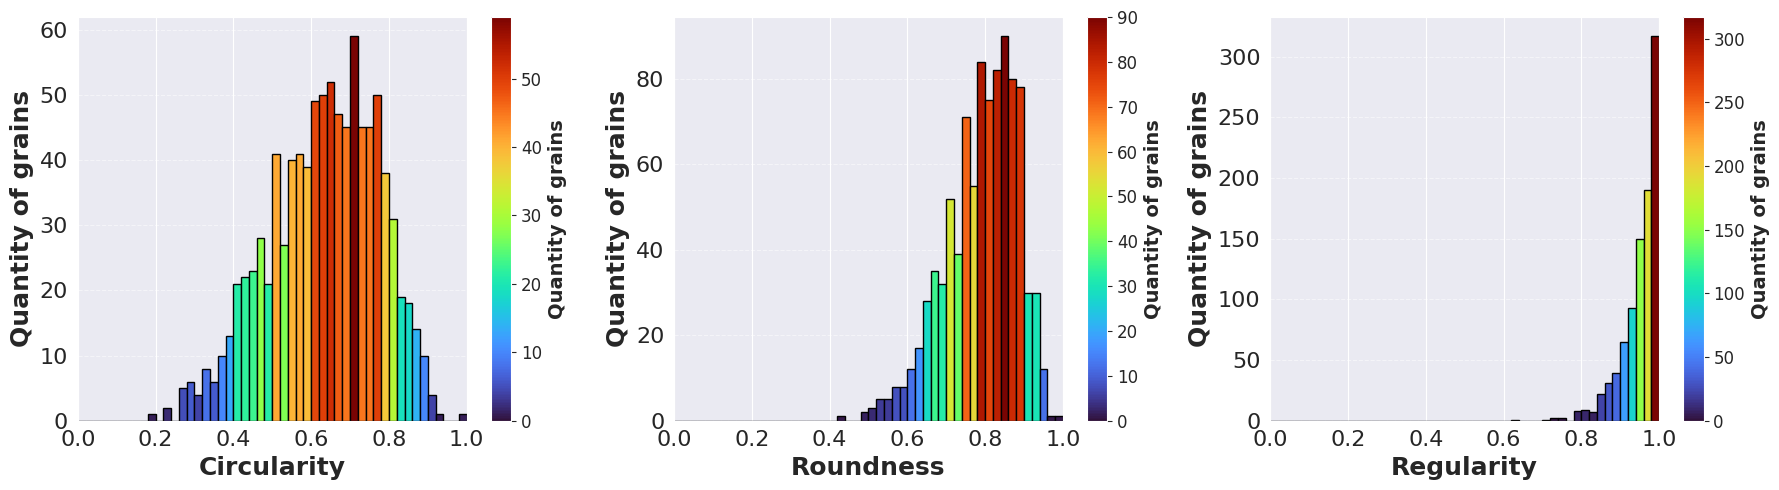


Resumo Estatístico:
       Circularidade  Arredondamento  Regularidade
count     937.000000      937.000000    937.000000
mean        0.632723        0.790056      0.951579
std         0.141183        0.092434      0.047652
min         0.186735        0.432128      0.634608
25%         0.536109        0.732195      0.931900
50%         0.643475        0.802169      0.964847
75%         0.738715        0.859485      0.986094
max         1.232805        1.110318      1.000000


In [26]:
# ==========================================================
# HISTOGRAMAS COM EIXO INTERPRETATIVO E VARIAÇÃO DE CORES
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize

def plot_shape_histograms_interpretative(df_shape, bins=25):

    if df_shape is None or len(df_shape) == 0:
        print("DataFrame vazio.")
        return

    descriptors = [
        ("Circularidade", "Circularity"),
        ("Arredondamento", "Roundness"),
        ("Regularidade", "Regularity")
    ]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, (col, xlabel) in zip(axes, descriptors):

        data = df_shape[col].dropna().values

        # -------------------------
        # Histograma manual
        # -------------------------
        counts, edges = np.histogram(data, bins=bins, range=(0, 1))
        widths = np.diff(edges)
        centers = edges[:-1]

        # -------------------------
        # Mapeamento de cores pela frequência
        # -------------------------
        norm = Normalize(vmin=np.min(counts), vmax=np.max(counts) if np.max(counts) > 0 else 1)
        cmap = cm.get_cmap("turbo")
        colors = cmap(norm(counts))

        # -------------------------
        # Plot das barras
        # -------------------------
        ax.bar(
            centers,
            counts,
            width=widths,
            align="edge",
            color=colors,
            edgecolor="black"
        )

        ax.set_xlabel(xlabel, fontsize=18, fontweight="bold")
        ax.set_ylabel("Quantity of grains", fontsize=18, fontweight="bold")
        ax.set_xlim(0, 1)
        ax.tick_params(axis='both', labelsize=16)
        ax.grid(axis="y", linestyle="--", alpha=0.5)

        # -------------------------
        # Barra de cores
        # -------------------------
        sm = cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax)
        cbar.set_label("Quantity of grains", fontsize=14, fontweight="bold")
        cbar.ax.tick_params(labelsize=12)

    plt.tight_layout()
    plt.show()

    print("\nResumo Estatístico:")
    print(df_shape[[d[0] for d in descriptors]].describe())


plot_shape_histograms_interpretative(df_shape, bins=50)

In [27]:
# ==========================================================
# DEFINIÇÃO DA POPULAÇÃO FIXA (H ≤ 170)
# ==========================================================

df_fourier = pd.DataFrame({
    "Label": results["labels"],
    "Harmônicos": results["harmonics"]
})

df_all = pd.merge(df_shape, df_fourier, on="Label", how="inner")

# 🔹 FILTRO PRINCIPAL
df_base = df_all[df_all["Harmônicos"] <= 170].copy()

N = len(df_base)

print(f"Total de grãos considerados (H ≤ 170): {N}")


# ----------------------------------------------------------
# FUNÇÃO PADRÃO (SEM RECALCULAR N)
# ----------------------------------------------------------

def frequency_table_fixed(data, bins, labels):

    categories = pd.cut(
        data,
        bins=bins,
        labels=labels,
        include_lowest=True,
        right=True
    )

    freq_abs = categories.value_counts().sort_index()
    freq_rel = (freq_abs / N) * 100
    freq_acum = freq_rel.cumsum()

    table = pd.DataFrame({
        "Frequência Absoluta": freq_abs,
        "Frequência (%)": freq_rel.round(2),
        "Frequência Acumulada (%)": freq_acum.round(2)
    })

    return table


# ==========================================================
# 1️⃣ HARMÔNICOS
# ==========================================================

bins_h = [0, 70, 100, 150, 170]
labels_h = ["0–70", "71–100", "101–150", "151–170"]

table_harmonics = frequency_table_fixed(
    df_base["Harmônicos"],
    bins_h,
    labels_h
)

print("\n========== HARMÔNICOS ==========\n")
display(table_harmonics)


# ==========================================================
# 2️⃣ CIRCULARIDADE
# ==========================================================

bins_ci = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
labels_ci = ["0.0–0.2", "0.2–0.4", "0.4–0.6", "0.6–0.8", "0.8–1.0"]

table_circularity = frequency_table_fixed(
    df_base["Circularidade"],
    bins_ci,
    labels_ci
)

print("\n========== CIRCULARIDADE ==========\n")
display(table_circularity)


# ==========================================================
# 3️⃣ ARREDONDAMENTO
# ==========================================================

bins_ro = [0.30, 0.50, 0.70, 0.85, 1.0]
labels_ro = ["0.30–0.50", "0.50–0.70", "0.70–0.85", "0.85–1.0"]

table_roundness = frequency_table_fixed(
    df_base["Arredondamento"],
    bins_ro,
    labels_ro
)

print("\n========== ARREDONDAMENTO ==========\n")
display(table_roundness)


# ==========================================================
# 4️⃣ REGULARIDADE
# ==========================================================

bins_re = [0.50, 0.70, 0.85, 0.95, 1.0]
labels_re = ["0.50–0.70", "0.70–0.85", "0.85–0.95", "0.95–1.0"]

table_regularity = frequency_table_fixed(
    df_base["Regularidade"],
    bins_re,
    labels_re
)

print("\n========== REGULARIDADE ==========\n")
display(table_regularity)

Total de grãos considerados (H ≤ 170): 814

========== HARMÔNICOS ==========



,Frequência Absoluta,Frequência (%),Frequência Acumulada (%)
Harmônicos,,,
0–70,386,47.42,47.42
71–100,109,13.39,60.81
101–150,176,21.62,82.43
151–170,143,17.57,100.00



========== CIRCULARIDADE ==========



,Frequência Absoluta,Frequência (%),Frequência Acumulada (%)
Circularidade,,,
0.0–0.2,0,0.00,0.00
0.2–0.4,18,2.21,2.21
0.4–0.6,232,28.50,30.71
0.6–0.8,465,57.13,87.84
0.8–1.0,98,12.04,99.88



========== ARREDONDAMENTO ==========



,Frequência Absoluta,Frequência (%),Frequência Acumulada (%)
Arredondamento,,,
0.30–0.50,0,0.00,0.00
0.50–0.70,88,10.81,10.81
0.70–0.85,452,55.53,66.34
0.85–1.0,273,33.54,99.88



========== REGULARIDADE ==========



,Frequência Absoluta,Frequência (%),Frequência Acumulada (%)
Regularidade,,,
0.50–0.70,0,0.00,0.00
0.70–0.85,7,0.86,0.86
0.85–0.95,229,28.13,28.99
0.95–1.0,578,71.01,100.00


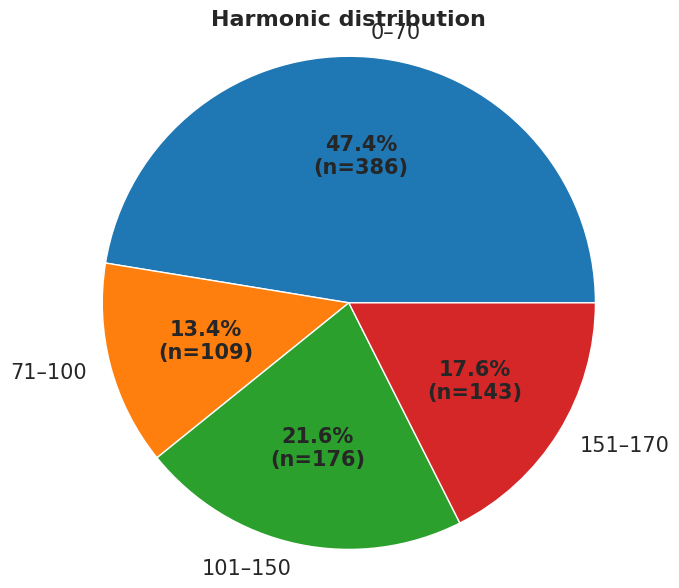

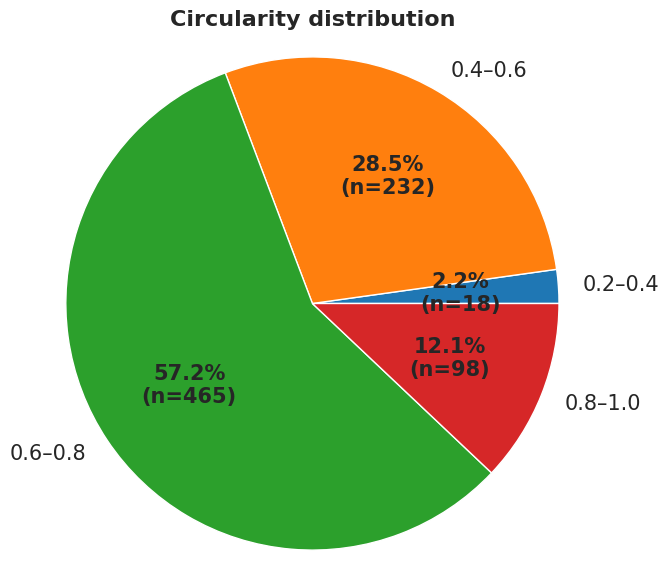

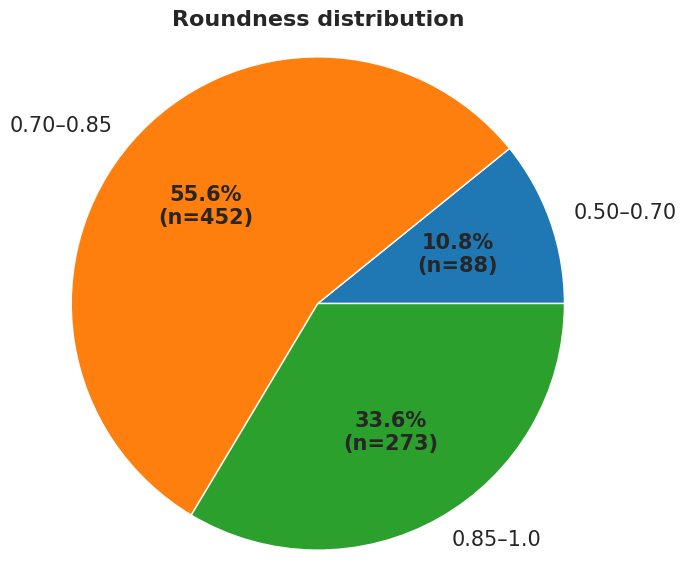

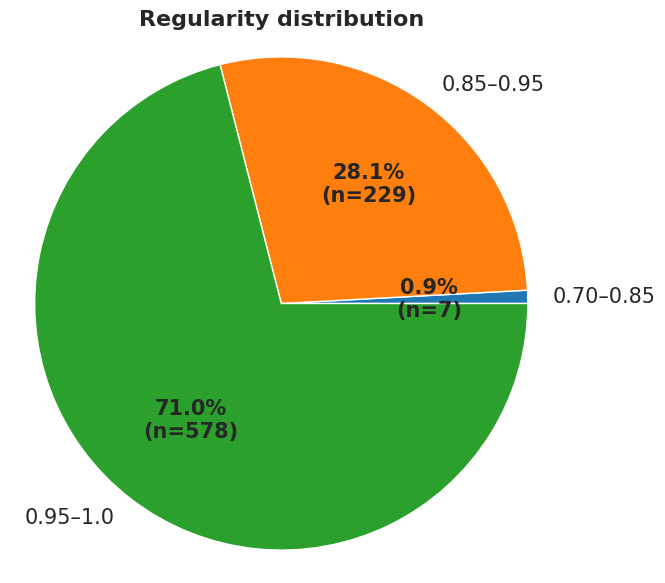

In [28]:
# ==========================================================
# FUNÇÃO PARA MOSTRAR % E N
# ==========================================================
def autopct_with_counts(values):
    def inner(pct):
        total = sum(values)
        count = int(round(pct * total / 100.0))
        return f"{pct:.1f}%\n(n={count})"
    return inner


def pie_from_table_counts(table, title):
    freq_abs = table["Frequência Absoluta"]
    freq_abs = freq_abs[freq_abs > 0]

    plt.figure(figsize=(7, 7))
    wedges, texts, autotexts = plt.pie(
        freq_abs,
        labels=freq_abs.index,
        autopct=autopct_with_counts(freq_abs.values),
        startangle=0
    )

    # Rótulos das classes
    for text in texts:
        text.set_fontsize(15)
        

    # Valores percentuais e contagens
    for autotext in autotexts:
        autotext.set_fontsize(15)
        autotext.set_fontweight("bold")

    plt.title(title, fontsize=16, fontweight="bold")
    plt.axis("equal")
    plt.show()


pie_from_table_counts(table_harmonics, "Harmonic distribution")
pie_from_table_counts(table_circularity, "Circularity distribution")
pie_from_table_counts(table_roundness, "Roundness distribution")
pie_from_table_counts(table_regularity, "Regularity distribution")

In [29]:
# Classification safeguard: circularity intervals are exploratory, NOT Wadell roundness.
# Powers/Folk per-grain maturity classes removed: their thresholds are not validated.
import pandas as pd
df_models = df_base.copy()
bins_ci_classes = [-float('inf'), 0.50, 0.70, 0.85, 0.95, float('inf')]
labels_ci_classes = ['Very low', 'Low', 'Moderate', 'High', 'Very high']
df_models['Circularity class (exploratory)'] = pd.cut(
    df_models['Circularidade'], bins=bins_ci_classes, labels=labels_ci_classes, right=False
)
table_circularity_classes = (df_models['Circularity class (exploratory)']
    .value_counts().reindex(labels_ci_classes, fill_value=0).rename_axis('Class').to_frame('n'))
table_circularity_classes['percent'] = 100 * table_circularity_classes['n'] / len(df_models)
display(table_circularity_classes)


,n,percent
Class,,
Very low,97,11.916462
Low,382,46.928747
Moderate,292,35.872236
High,41,5.036855
Very high,2,0.245700
